# EXP-E2-05 : apprendre avec des fenêtres masquées rend-il le MLP robuste aux pannes ?

**Question** (comparaison individuelle d'Idir). Le MLP lit la dernière semaine publiée. Quand un capteur tombe en panne, la semaine est trouée. Sous 84 h mesurées, le MLP refuse et la référence prend le relais. Un MLP **appris avec des semaines artificiellement masquées** (B) prévoit-il mieux sur des semaines incomplètes, sans perdre sur les semaines complètes ?

**Bras** ([fiche](../reports/experiments/EXP-E2-05.md), figée le 2026-11-24) :

| Bras | Modèle | Seuil en prévision |
| --- | --- | --- |
| A | MLP actuel (3 graines) | 84 h |
| A′ | les mêmes poids | 24 h |
| B | MLP appris avec masquage (10 % des exemples, un bloc de 24 à 144 h ; 3 graines) | 24 h |
| R | médiane des 4 semaines | sans objet |

**A′ contre B isole le masquage** : même seuil, seul l'apprentissage change.

**Niveaux de dégradation**, appliqués à la semaine visible des 6 014 cas, avec les mêmes trous pour tous les bras :
- `d0` : rien ;
- `panne-48`, `panne-96`, `panne-144` : les N dernières heures ;
- `trous-50` : la moitié des heures, au hasard.

**Règle, figée avant les scores** (moyennes des 3 graines, lecture système). B remplace A seulement si les deux conditions sont vraies :
1. sur `d0` et sur les semaines complètes, la MAE de B ne dépasse pas celle de A de plus que l'étendue entre graines de A ;
2. sur `panne-96` et `panne-144`, B fait mieux que A′ d'au moins la plus grande étendue entre graines de A′ et de B.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.models.known import batch as B
from src.models.known import demo as D
from src.models.known import predict as P
from src.models.known import score as S

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
SNAPSHOT = "hist-20261117"
PRED = P.data_path("predictions")

LEVELS = list(B.DEGRADATION_LEVELS)
A = ["e2-mlp-ctx-20260701-s0-9ce9", "e2-mlp-ctx-20260701-s1-9318", "e2-mlp-ctx-20260701-s2-6278"]
BM = ["e2-mlp-ctx-20260701-s0-37f5", "e2-mlp-ctx-20260701-s1-bd12", "e2-mlp-ctx-20260701-s2-f26e"]

def arm(method_run_id):
    base = method_run_id.rsplit("_", 1)[0]
    if base.startswith("e2-reference"):
        return "R"
    if base.endswith("-seuil24"):
        return "A′"
    return "A" if base in A else "B"

## 1. Scores par niveau de dégradation

Chaque niveau est noté par `python -m src.models.known.score --experiment EXP-E2-05 --level <niveau>`.

In [2]:
rows = []
for level in LEVELS:
    path = PRED / "EXP-E2-05" / level / "scores_known_site_validation.json"
    if not path.exists():
        print("pas encore noté :", level); continue
    js = json.loads(path.read_text())["scores"]
    for lecture, table in js.items():
        for mid, v in table.items():
            rows.append({"niveau": level, "lecture": lecture, "bras": arm(mid), "run": mid, **v})
long = pd.DataFrame(rows)
summary = (long.groupby(["lecture", "niveau", "bras"])["mae_macro"]
           .agg(moyenne="mean", étendue=lambda s: s.max() - s.min(), graines="count")
           .reset_index())
summary["niveau"] = pd.Categorical(summary["niveau"], LEVELS, ordered=True)
summary.sort_values(["lecture", "niveau", "bras"]).pivot_table(
    index=["lecture", "niveau"], columns="bras", values="moyenne", observed=True).round(2)

bras                   A     A′      B      R
lecture niveau                               
brut    d0         22.36  22.36  22.73  27.00
        panne-48   27.92  27.92  25.19  26.98
        panne-96     NaN  36.47  26.11  26.97
        panne-144    NaN  46.31  27.34  29.37
        trous-50   25.31  25.31  23.33  27.47
système d0         22.39  22.37  22.73  27.01
        panne-48   27.93  27.91  25.17  27.01
        panne-96   29.75  36.45  26.15  27.01
        panne-144  28.49  46.00  28.20  30.26
        trous-50   27.36  27.74  25.69  28.64

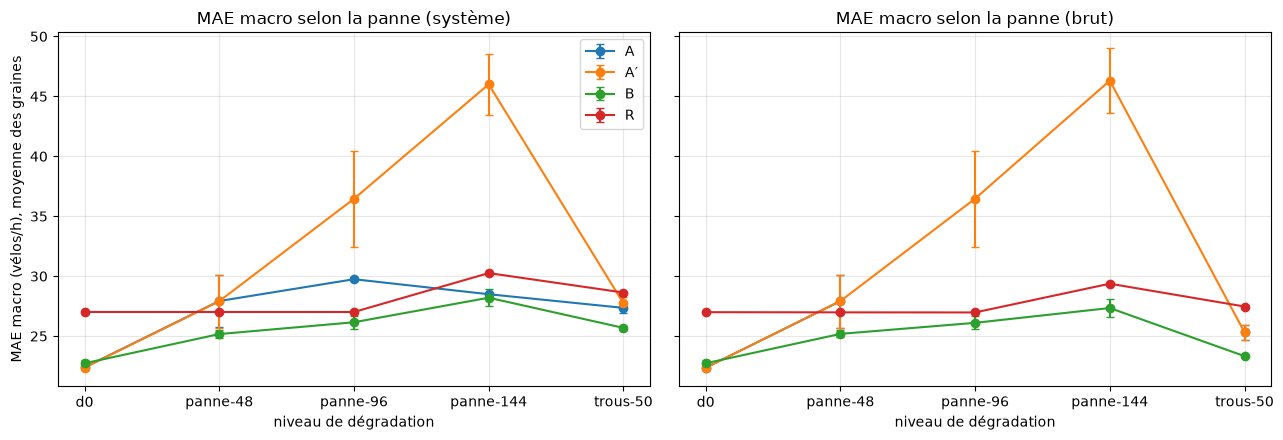

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, lecture in zip(axes, ["système", "brut"]):
    s = summary[summary.lecture == lecture].sort_values("niveau")
    for name, g in s.groupby("bras"):
        ax.errorbar(g["niveau"].astype(str), g["moyenne"], yerr=g["étendue"] / 2, marker="o", capsize=3, label=name)
    ax.set_title(f"MAE macro selon la panne ({lecture})"); ax.set_xlabel("niveau de dégradation"); ax.grid(alpha=0.3)
axes[0].set_ylabel("MAE macro (vélos/h), moyenne des graines"); axes[0].legend()
plt.tight_layout()

## 2. Couverture : qui sert, qui se replie

In [4]:
long[long.lecture == "brut"].pivot_table(index="niveau", columns="bras", values="coverage_24h", aggfunc="mean").reindex(LEVELS).round(3)

bras,A,A′,B,R
niveau,,,,
d0,0.947,0.954,0.954,1.0
panne-48,0.944,0.953,0.953,1.0
panne-96,0.000,0.950,0.950,1.0
panne-144,0.000,0.895,0.895,1.0
trous-50,0.681,0.952,0.952,1.0


## 3. Semaines naturellement incomplètes (`d0`, par tranche d'heures mesurées)

Les tranches viennent des vraies semaines visibles, sans effacement. Le calcul prend quelques minutes.

In [5]:
cases = S.load_cases()
loader = P.counts_history_loader(SNAPSHOT)
band = D.observed_hours_band(cases, loader)
print(band.value_counts())
del loader  # libère environ 1 Go avant de charger les 10 prévisions de d0
import gc; gc.collect()
fc_d0 = S.load_forecasts(PRED / "EXP-E2-05" / "d0")
obs = S.load_observations(cases)
strata = S.score_by_group(cases, fc_d0, obs, band).reset_index()
strata["bras"] = strata.method_run_id.map(arm)
strata.groupby(["group", "bras"])["mae_macro"].agg(["mean", lambda s: s.max() - s.min(), "count"]).round(2)

observed_band
168-140 h    5659
< 24 h        274
83-24 h        46
139-84 h       35
Name: count, dtype: int64


mean  <lambda_0>  count
group     bras                          
139-84 h  A     18.31        2.19      3
          A′    18.31        2.19      3
          B     17.07        0.40      3
          R     29.56        0.00      1
168-140 h A     22.38        0.36      3
          A′    22.38        0.36      3
          B     22.77        0.54      3
          R     26.98        0.00      1
83-24 h   A     24.14        0.00      3
          A′    18.36        0.34      3
          B     15.68        0.43      3
          R     24.59        0.00      1
< 24 h    A     39.01        0.00      3
          A′    39.01        0.00      3
          B     39.01        0.00      3
          R     40.39        0.00      1

## 4. La règle de décision, appliquée telle quelle

In [6]:
sysm = summary[summary.lecture == "système"].set_index(["niveau", "bras"])
def mean(level, b): return float(sysm.loc[(level, b), "moyenne"])
def spread(level, b): return float(sysm.loc[(level, b), "étendue"])

full = strata[strata.group == "168-140 h"].groupby("bras")["mae_macro"]
c1_d0 = mean("d0", "B") - mean("d0", "A") <= spread("d0", "A")
c1_full = full.mean()["B"] - full.mean()["A"] <= (full.max()["A"] - full.min()["A"])
c2 = all(mean(l, "A′") - mean(l, "B") >= max(spread(l, "A′"), spread(l, "B")) for l in ["panne-96", "panne-144"])
print(f"1a. d0 : B - A = {mean('d0','B') - mean('d0','A'):+.3f} ; étendue A = {spread('d0','A'):.3f} -> {'oui' if c1_d0 else 'non'}")
print(f"1a. semaines complètes : B - A = {full.mean()['B'] - full.mean()['A']:+.3f} -> {'oui' if c1_full else 'non'}")
for l in ["panne-96", "panne-144"]:
    print(f"1b. {l} : A′ - B = {mean(l,'A′') - mean(l,'B'):+.3f} ; étendue max = {max(spread(l,'A′'), spread(l,'B')):.3f}")
print("=> décision :", "B remplace A" if (c1_d0 and c1_full and c2) else "on garde A et son repli")
for l in LEVELS:
    print(f"   B face à R sur {l} : {mean(l,'B') - mean(l,'R'):+.2f} vélos/h")

1a. d0 : B - A = +0.340 ; étendue A = 0.357 -> oui
1a. semaines complètes : B - A = +0.387 -> non
1b. panne-96 : A′ - B = +10.298 ; étendue max = 7.967
1b. panne-144 : A′ - B = +17.802 ; étendue max = 5.057
=> décision : on garde A et son repli
   B face à R sur d0 : -4.28 vélos/h
   B face à R sur panne-48 : -1.84 vélos/h
   B face à R sur panne-96 : -0.86 vélos/h
   B face à R sur panne-144 : -2.06 vélos/h
   B face à R sur trous-50 : -2.95 vélos/h


## 5. Un cas en direct : une panne de 96 h

Le même cas, d'abord sur la vraie semaine, puis avec les 96 dernières heures effacées. A refuse alors (72 h < 84 h) et se replie. A′ et B prévoient avec les 72 h restantes.

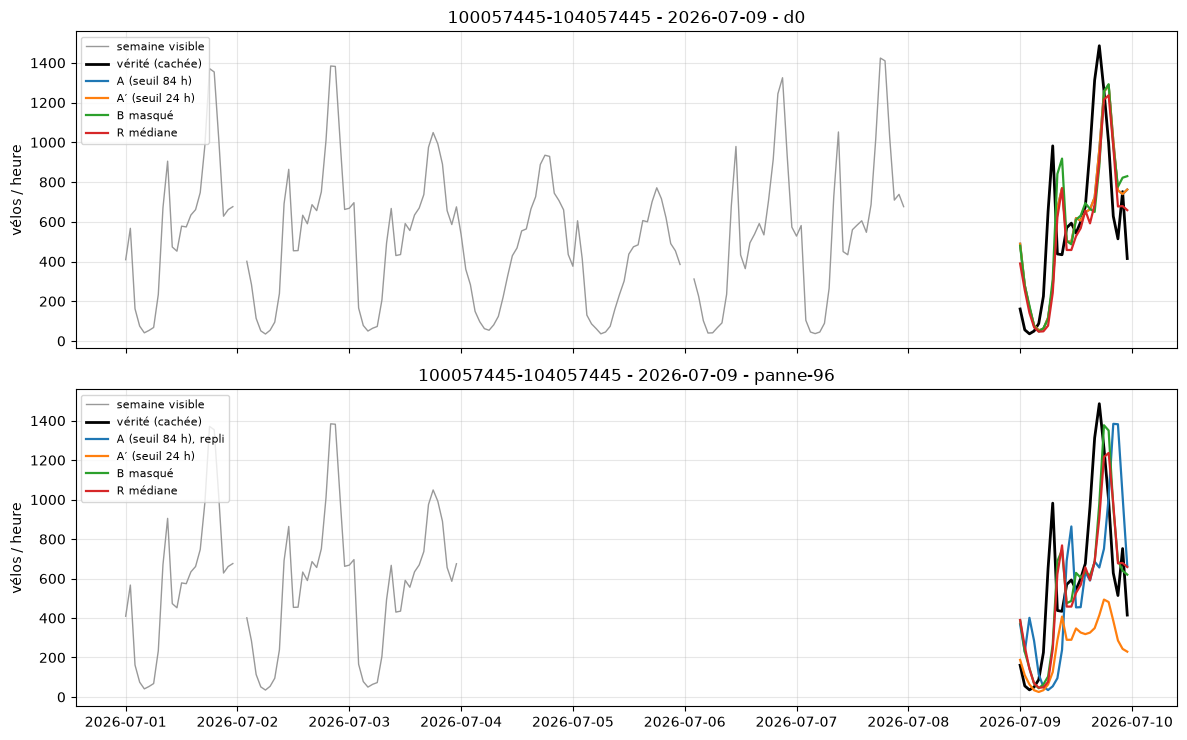

In [7]:
del fc_d0, obs; gc.collect()
loader = P.counts_history_loader(SNAPSHOT)
context = P.load_context(SNAPSHOT)
all_cases = pd.read_csv("data/evaluation/proto-v1/cases.csv", dtype=str, keep_default_na=False)
COUNTER, DAY = "100057445-104057445", "2026-07-09"
case = D.find_case(all_cases, COUNTER, DAY)
VARIANTS = {"A (seuil 84 h)": {"variant": "mlp", "model_run_id": A[0]},
            "A′ (seuil 24 h)": {"variant": "mlp", "model_run_id": A[0], "min_observed_hours": 24},
            "B masqué": {"variant": "mlp", "model_run_id": BM[0]},
            "R médiane": {"variant": "reference_profile"}}
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
for ax, level in zip(axes, ["d0", "panne-96"]):
    history = B.degrade_history(loader(COUNTER), case, level, P.default_publication_lag())
    fc = D.forecast_case(case, history, VARIANTS, context=context)
    D.plot_case(D.case_view(case, history), fc, ax=ax, title=f"{COUNTER} - {DAY} - {level}")
plt.tight_layout()

## 6. Tout recalculer (optionnel)

Il faut passer `RECALCULER = True`. Un niveau entier (10 calculs) prend environ 25 min et son score environ 8 min. La commande est dans la fiche (point 8).

In [8]:
RECALCULER = False
if RECALCULER:
    again = S.score_experiment(PRED / "EXP-E2-05" / "panne-96")
    display(again["système"])